1) Carregando imagem...
2) Pré-processando imagem...
3) Criando máscara binária...
4) Limpando máscara...
5) Gerando marcadores...
   Marcadores detectados: 1195
6) Aplicando watershed...
7) Filtrando grãos finais...
   Total de grãos segmentados: 1032
8) Criando visualizações...


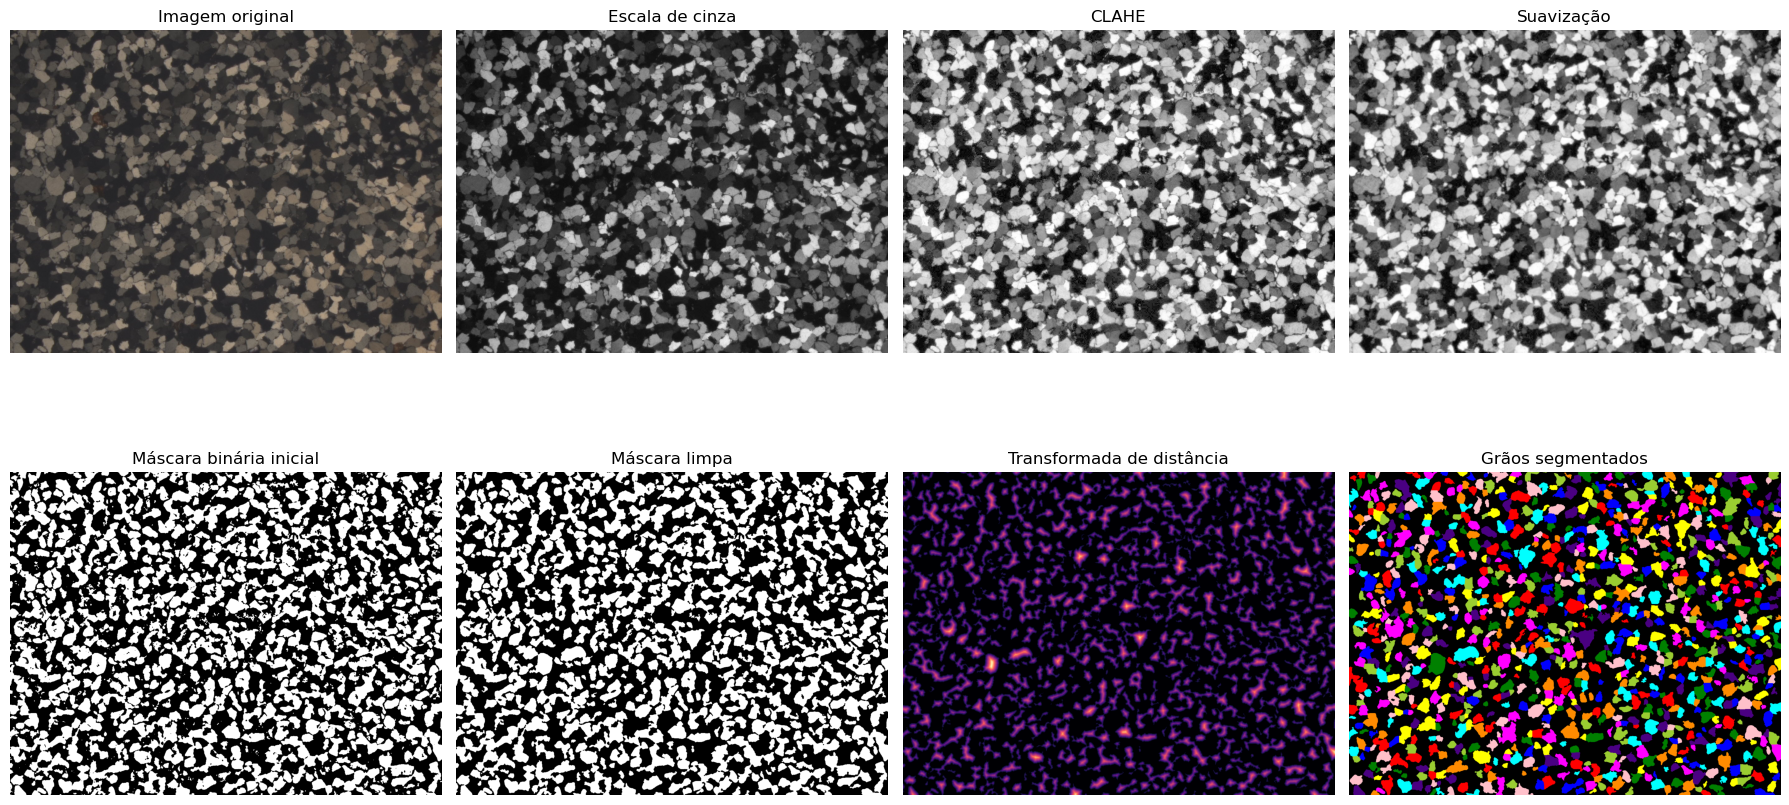

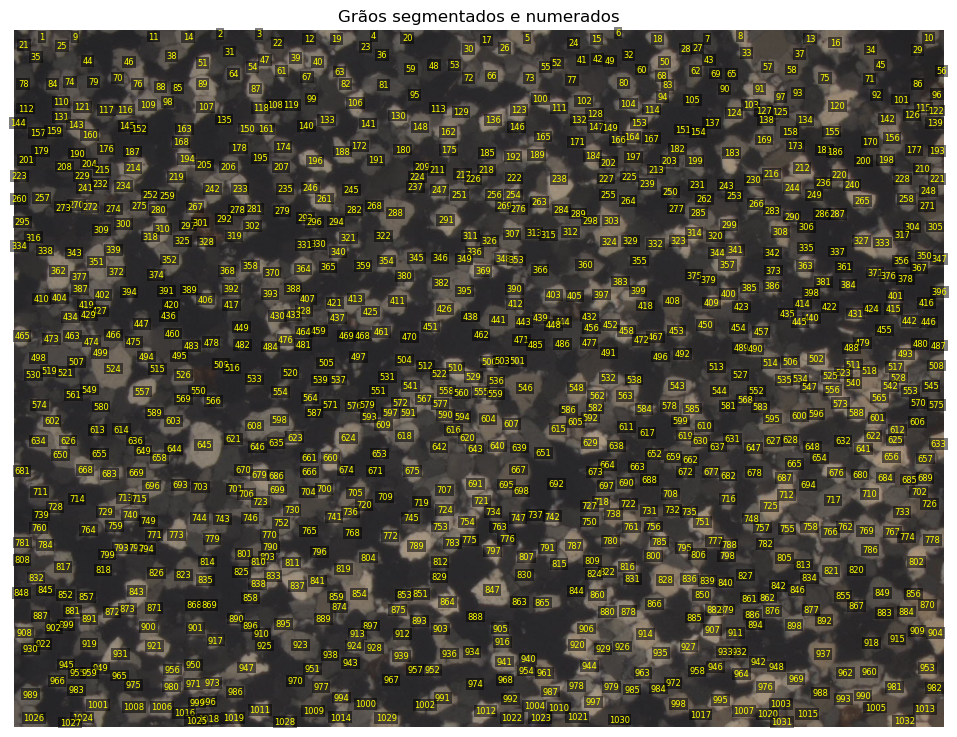

9) Exportando grãos individuais...
10) Exportando medidas...

Resumo das primeiras linhas:
   label    area   perimeter  eccentricity  solidity    extent  \
0      1   517.0   98.183766      0.141197  0.897569  0.738571   
1      2   319.0   72.763456      0.764390  0.930029  0.766827   
2      3   435.0   91.597980      0.851938  0.953947  0.635965   
3      4   584.0  115.254834      0.826952  0.848837  0.713065   
4      5  1229.0  194.539105      0.767528  0.787821  0.495764   

   major_axis_length  minor_axis_length  equivalent_diameter  centroid-0  \
0          26.693410          26.425984            25.656673   10.640232   
1          25.690060          16.563770            20.153496    6.463950   
2          34.154104          17.884529            23.534213    6.372414   
3          37.416310          21.038156            27.268515    8.844178   
4          59.098902          37.883286            39.557697   12.316517   

   centroid-1  bbox-0  bbox-1  bbox-2  bbox-3  circular

In [2]:
# ============================================================
# Segmentation and separation of grains in petrographic images
# Method:
# 1. Read image
# 2. Convert to grayscale
# 3. Enhance contrast using CLAHE
# 4. Smoothing
# 5. Generate binary mask
# 6. Morphological cleanup
# 7. Distance transform
# 8. Local maxima as markers
# 9. Marker-controlled watershed
# 10. Label, visualize, and export grains
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy import ndimage as ndi

from skimage import io, color, exposure, filters, morphology, measure, segmentation, feature, util
from skimage.segmentation import watershed, find_boundaries
from skimage.measure import regionprops_table
import pandas as pd


# ============================================================
# MAIN SETTINGS
# ============================================================

IMAGE_PATH = "/home/victor/analise_sinais_2025/joelson/2LFST1AM/Lâmina Faro 41 obj. 2,5x b Nx.jpg"
OUTPUT_DIR = "saida_segmentacao_graos01"

# Adjustable parameters
CLAHE_CLIP_LIMIT = 2.5
GAUSSIAN_SIGMA = 1.0

# Local threshold (odd and relatively large to account for local variation)
LOCAL_BLOCK_SIZE = 71
LOCAL_OFFSET = -5

# Morphological cleanup
MIN_OBJECT_AREA = 120      # remove objetos muito pequenos
MIN_HOLE_AREA = 50         # preenche pequenos buracos internos
MORPH_DISK_SIZE = 1

# Markers / Watershed
MIN_DISTANCE_PEAKS = 10    # distância mínima entre centros de grãos
FOOTPRINT_SIZE = 15        # tamanho da vizinhança para máximos locais

# Final grain filter
FINAL_MIN_AREA = 150
FINAL_MAX_AREA = None      # pode definir, ex.: 20000


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def ensure_dir(path):
    os.makedirs(path, exist_ok=True)


def load_image(image_path):
    """
    Carrega imagem RGB.
    """
    img = io.imread(image_path)

    # Ensure RGB
    if img.ndim == 2:
        img = color.gray2rgb(img)
    elif img.shape[2] == 4:
        img = img[:, :, :3]

    return img


def preprocess_image(rgb_img, clahe_clip=2.5, gaussian_sigma=1.0):
    """
    Pré-processamento:
    - converte para escala de cinza
    - aplica CLAHE
    - aplica suavização gaussiana
    """
    gray = color.rgb2gray(rgb_img)  # float [0,1]

    # CLAHE
    gray_eq = exposure.equalize_adapthist(gray, clip_limit=clahe_clip)

    # Smoothing
    gray_smooth = filters.gaussian(gray_eq, sigma=gaussian_sigma)

    return gray, gray_eq, gray_smooth


def build_binary_mask(gray_smooth, block_size=71, offset=-5):
    """
    Gera máscara binária dos grãos.
    Usa threshold local para melhor adaptação à variação de iluminação/contraste.
    """
    # Convert to uint8 for consistent local thresholding
    gray_u8 = util.img_as_ubyte(gray_smooth)

    local_thresh = filters.threshold_local(gray_u8, block_size=block_size, offset=offset)
    binary = gray_u8 > local_thresh

    return binary


def clean_mask(binary_mask,
               min_object_area=120,
               min_hole_area=50,
               morph_disk_size=1):
    """
    Limpeza da máscara:
    - remoção de pequenos objetos
    - preenchimento de pequenos buracos
    - opening/closing leves
    """
    cleaned = morphology.remove_small_objects(binary_mask.astype(bool), min_size=min_object_area)
    cleaned = morphology.remove_small_holes(cleaned, area_threshold=min_hole_area)

    selem = morphology.disk(morph_disk_size)
    cleaned = morphology.opening(cleaned, selem)
    cleaned = morphology.closing(cleaned, selem)

    return cleaned


def generate_markers(cleaned_mask,
                     min_distance_peaks=10,
                     footprint_size=15):
    """
    Gera marcadores internos a partir da transformada de distância.
    """
    distance = ndi.distance_transform_edt(cleaned_mask)

    coords = feature.peak_local_max(
        distance,
        min_distance=min_distance_peaks,
        footprint=np.ones((footprint_size, footprint_size)),
        labels=cleaned_mask
    )

    markers_mask = np.zeros(distance.shape, dtype=bool)
    if len(coords) > 0:
        markers_mask[tuple(coords.T)] = True

    markers, _ = ndi.label(markers_mask)

    return distance, markers, coords


def apply_watershed(cleaned_mask, distance, markers):
    """
    Aplica watershed controlado por marcadores.
    """
    labels = watershed(-distance, markers, mask=cleaned_mask)
    return labels


def filter_labeled_grains(labels, min_area=150, max_area=None):
    """
    Filtra grãos segmentados com base em área.
    """
    props = measure.regionprops(labels)
    filtered = np.zeros_like(labels, dtype=np.int32)

    new_id = 1
    for region in props:
        area = region.area
        if area < min_area:
            continue
        if max_area is not None and area > max_area:
            continue

        filtered[labels == region.label] = new_id
        new_id += 1

    return filtered


def create_overlay(rgb_img, labels):
    """
    Cria imagem com contornos dos grãos sobrepostos à imagem original.
    """
    overlay = rgb_img.copy()
    boundaries = find_boundaries(labels > 0, mode='outer')

    # Draw boundaries in red
    overlay[boundaries] = [255, 0, 0]

    return overlay


def create_labeled_preview(rgb_img, labels):
    """
    Cria preview com numeração dos grãos.
    """
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(rgb_img)
    ax.set_title("Grãos segmentados e numerados")
    ax.axis("off")

    props = measure.regionprops(labels)
    for region in props:
        y, x = region.centroid
        ax.text(
            x, y, str(region.label),
            color='yellow',
            fontsize=6,
            ha='center', va='center',
            bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=1)
        )

    return fig, ax


def save_individual_grains(rgb_img, labels, output_dir):
    """
    Salva cada grão individualmente:
    - recorte da bounding box
    - máscara do grão
    - imagem RGB com fundo preto
    """
    grains_dir = os.path.join(output_dir, "graos_individuais")
    masks_dir = os.path.join(output_dir, "mascaras_individuais")
    ensure_dir(grains_dir)
    ensure_dir(masks_dir)

    props = measure.regionprops(labels)

    for region in props:
        grain_id = region.label
        minr, minc, maxr, maxc = region.bbox

        grain_mask = (labels[minr:maxr, minc:maxc] == grain_id)
        grain_crop = rgb_img[minr:maxr, minc:maxc].copy()

        # Black background outside the grain
        isolated = np.zeros_like(grain_crop)
        isolated[grain_mask] = grain_crop[grain_mask]

        grain_filename = os.path.join(grains_dir, f"grao_{grain_id:04d}.png")
        mask_filename = os.path.join(masks_dir, f"mask_grao_{grain_id:04d}.png")

        io.imsave(grain_filename, isolated)
        io.imsave(mask_filename, (grain_mask.astype(np.uint8) * 255))


def export_measurements(labels, output_dir):
    """
    Exporta tabela com propriedades morfológicas básicas.
    """
    props = regionprops_table(
        labels,
        properties=(
            "label",
            "area",
            "perimeter",
            "eccentricity",
            "solidity",
            "extent",
            "major_axis_length",
            "minor_axis_length",
            "equivalent_diameter",
            "centroid",
            "bbox"
        )
    )

    df = pd.DataFrame(props)

    # circularity = 4*pi*A / P²
    if "perimeter" in df.columns:
        df["circularidade"] = np.where(
            df["perimeter"] > 0,
            4 * np.pi * df["area"] / (df["perimeter"] ** 2),
            np.nan
        )

    csv_path = os.path.join(output_dir, "medidas_graos.csv")
    df.to_csv(csv_path, index=False)

    return df


def plot_processing_steps(rgb_img, gray, gray_eq, gray_smooth, binary, cleaned, distance, labels, output_dir):
    """
    Salva figura resumo com as etapas principais
    e também salva individualmente cada axis exibido.
    """
    fig, axes = plt.subplots(2, 4, figsize=(18, 10))
    axes = axes.ravel()

    axes[0].imshow(rgb_img)
    axes[0].set_title("Imagem original")
    axes[0].axis("off")

    axes[1].imshow(gray, cmap="gray")
    axes[1].set_title("Escala de cinza")
    axes[1].axis("off")

    axes[2].imshow(gray_eq, cmap="gray")
    axes[2].set_title("CLAHE")
    axes[2].axis("off")

    axes[3].imshow(gray_smooth, cmap="gray")
    axes[3].set_title("Suavização")
    axes[3].axis("off")

    axes[4].imshow(binary, cmap="gray")
    axes[4].set_title("Máscara binária inicial")
    axes[4].axis("off")

    axes[5].imshow(cleaned, cmap="gray")
    axes[5].set_title("Máscara limpa")
    axes[5].axis("off")

    axes[6].imshow(distance, cmap="magma")
    axes[6].set_title("Transformada de distância")
    axes[6].axis("off")

    axes[7].imshow(color.label2rgb(labels, bg_label=0))
    axes[7].set_title("Grãos segmentados")
    axes[7].axis("off")

    plt.tight_layout()

    # Save complete figure
    fig_path = os.path.join(output_dir, "etapas_processamento.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")

    # Save each axis separately
    axes_dir = os.path.join(output_dir, "axes_individuais")
    ensure_dir(axes_dir)

    axis_data = [
        ("01_imagem_original.png", rgb_img, None),
        ("02_escala_de_cinza.png", gray, "gray"),
        ("03_clahe.png", gray_eq, "gray"),
        ("04_suavizacao.png", gray_smooth, "gray"),
        ("05_mascara_binaria_inicial.png", binary, "gray"),
        ("06_mascara_limpa.png", cleaned, "gray"),
        ("07_transformada_distancia.png", distance, "magma"),
        ("08_graos_segmentados.png", color.label2rgb(labels, bg_label=0), None),
    ]

    for filename, image, cmap in axis_data:
        fig_axis, ax_axis = plt.subplots(figsize=(6, 6))
        if cmap is None:
            ax_axis.imshow(image)
        else:
            ax_axis.imshow(image, cmap=cmap)
        ax_axis.axis("off")
        plt.tight_layout()
        save_path = os.path.join(axes_dir, filename)
        fig_axis.savefig(save_path, dpi=300, bbox_inches="tight", pad_inches=0)
        plt.close(fig_axis)

    plt.show()


# ============================================================
# MAIN EXECUTION
# ============================================================

def main():
    ensure_dir(OUTPUT_DIR)

    print("1) Carregando imagem...")
    rgb_img = load_image(IMAGE_PATH)

    print("2) Pré-processando imagem...")
    gray, gray_eq, gray_smooth = preprocess_image(
        rgb_img,
        clahe_clip=CLAHE_CLIP_LIMIT,
        gaussian_sigma=GAUSSIAN_SIGMA
    )

    print("3) Criando máscara binária...")
    binary = build_binary_mask(
        gray_smooth,
        block_size=LOCAL_BLOCK_SIZE,
        offset=LOCAL_OFFSET
    )

    print("4) Limpando máscara...")
    cleaned = clean_mask(
        binary,
        min_object_area=MIN_OBJECT_AREA,
        min_hole_area=MIN_HOLE_AREA,
        morph_disk_size=MORPH_DISK_SIZE
    )

    print("5) Gerando marcadores...")
    distance, markers, coords = generate_markers(
        cleaned,
        min_distance_peaks=MIN_DISTANCE_PEAKS,
        footprint_size=FOOTPRINT_SIZE
    )

    print(f"   Marcadores detectados: {markers.max()}")

    print("6) Aplicando watershed...")
    labels = apply_watershed(cleaned, distance, markers)

    print("7) Filtrando grãos finais...")
    labels_filtered = filter_labeled_grains(
        labels,
        min_area=FINAL_MIN_AREA,
        max_area=FINAL_MAX_AREA
    )

    n_grains = labels_filtered.max()
    print(f"   Total de grãos segmentados: {n_grains}")

    def separate_touching_grains(labels, gap_size=1):
        """
        Cria espaço entre grãos já rotulados, removendo as fronteiras entre rótulos
        vizinhos e ampliando esse espaço com espessura controlada.

        Parâmetros
        ----------
        labels : ndarray
            Imagem rotulada final dos grãos.
        gap_size : int
            Espessura do espaço criado entre grãos.
            1 = separação fina
            2 = separação moderada
            3 = separação mais forte

        Retorna
        -------
        separated_labels : ndarray
            Nova imagem rotulada com espaço entre grãos.
        separated_mask : ndarray
            Máscara binária com os grãos separados.
        """
        separated_labels = labels.copy()

        # Detect boundaries between adjacent labels
        boundaries = find_boundaries(labels, mode='outer')

        # Increase gap thickness if desired
        if gap_size > 1:
            selem = morphology.disk(gap_size)
            boundaries = morphology.binary_dilation(boundaries, selem)

        # Remove boundaries from the labeled image
        separated_labels[boundaries] = 0

        # Relabel after removing boundaries
        separated_labels = measure.label(separated_labels > 0, connectivity=1)

        separated_mask = separated_labels > 0

        return separated_labels, separated_mask
    
    def save_separated_grains_tif(rgb_img, separated_mask, output_dir, filename="graos_separados.tif"):
        """
        Salva uma imagem .tif com os grãos separados por espaço vazio.
        O fundo fica preto e os grãos mantêm a textura original da imagem RGB.
        """
        separated_rgb = np.zeros_like(rgb_img)
        separated_rgb[separated_mask] = rgb_img[separated_mask]

        tif_path = os.path.join(output_dir, filename)
        io.imsave(tif_path, separated_rgb)

        return tif_path

    

    print("8) Criando visualizações...")
    overlay = create_overlay(rgb_img, labels_filtered)

    io.imsave(os.path.join(OUTPUT_DIR, "overlay_contornos.png"), overlay)
    io.imsave(os.path.join(OUTPUT_DIR, "mascara_final.png"), (labels_filtered > 0).astype(np.uint8) * 255)

    plot_processing_steps(
        rgb_img, gray, gray_eq, gray_smooth,
        binary, cleaned, distance, labels_filtered,
        OUTPUT_DIR
    )

    fig, ax = create_labeled_preview(rgb_img, labels_filtered)
    preview_path = os.path.join(OUTPUT_DIR, "graos_numerados.png")
    plt.savefig(preview_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("9) Exportando grãos individuais...")
    save_individual_grains(rgb_img, labels_filtered, OUTPUT_DIR)

    print("10) Exportando medidas...")
    df = export_measurements(labels_filtered, OUTPUT_DIR)

    print("\nResumo das primeiras linhas:")
    print(df.head())

    print(f"\nArquivos salvos em: {os.path.abspath(OUTPUT_DIR)}")


if __name__ == "__main__":
    main()

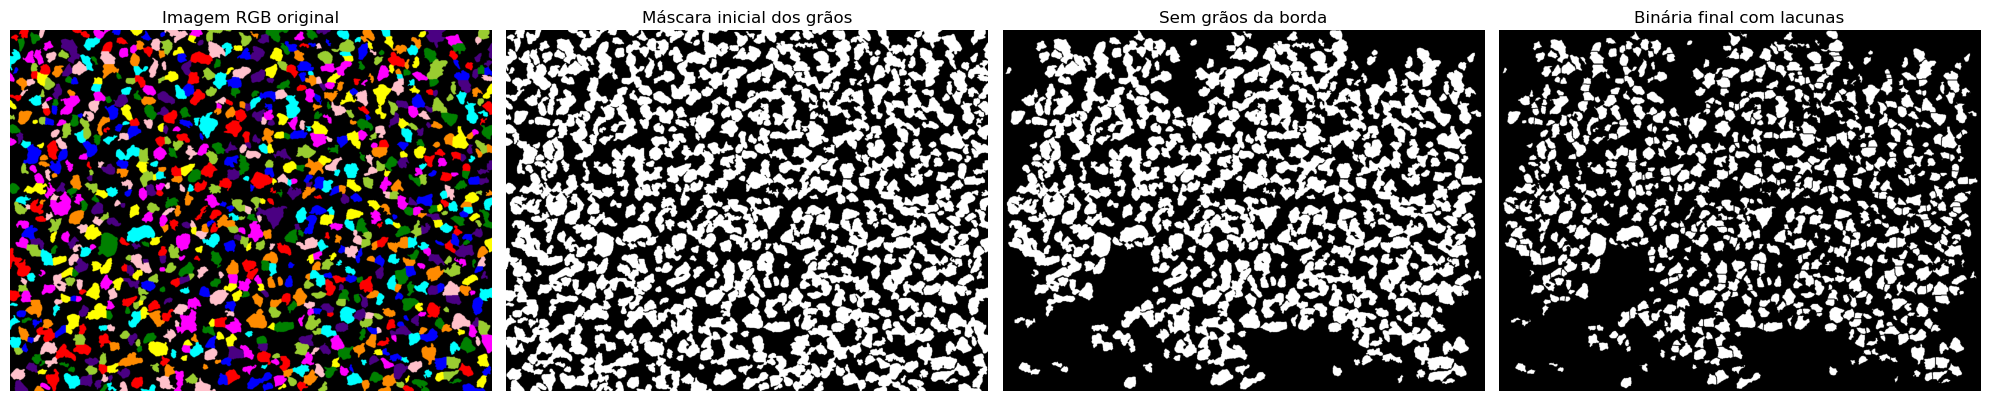

Imagem salva em: /home/victor/analise_sinais_2025/joelson/2LFST1AM/saida_segmentacao_graos/08_graos_binaria_sem_borda_com_lacuna01.png
Total de cores/grãos detectáveis: 8018


In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt

from skimage.io import imread, imsave
from skimage.morphology import binary_erosion, disk
from skimage.segmentation import clear_border


# ============================================================
# 1. Load segmented RGB image
# ============================================================
image_path = "/home/victor/analise_sinais_2025/joelson/2LFST1AM/projeto/saida_segmentacao_graos01/axes_individuais/08_graos_segmentados.png"   # ajuste se necessário
img = imread(image_path)

# Ensure RGB
if img.ndim == 2:
    raise ValueError("A imagem está em escala de cinza; era esperado RGB.")
if img.shape[-1] == 4:
    img = img[..., :3]  # remove alfa se existir


# ============================================================
# 2. Detect black background and colored grains
# ============================================================
# Background = pixels [0,0,0]
background = np.all(img == [0, 0, 0], axis=-1)

# Initial grain mask (any nonblack pixel)
grain_mask = ~background


# ============================================================
# 3. Remove grains truncated at image borders
# ============================================================
# clear_border removes connected components touching the border.
# Because grains are colored, first use the full binary mask.
mask_no_border = clear_border(grain_mask)


# ============================================================
# 4. Identify each color present in the image
# ============================================================
# Extract all unique nonblack colors
pixels = img.reshape(-1, 3)
unique_colors = np.unique(pixels, axis=0)

# Remove black
unique_colors = unique_colors[np.any(unique_colors != [0, 0, 0], axis=1)]


# ============================================================
# 5. Create gaps between grains of different colors
# ============================================================
# Strategy:
# - For each color, create a mask
# - Intersect with mask_no_border
# - Apply mild erosion
# - Combine everything into a single binary mask
#
# The radius controls the resulting gap:
# disk(1) = mild separation
# disk(2) = stronger separation
erosion_radius = 1
selem = disk(erosion_radius)

final_binary = np.zeros(mask_no_border.shape, dtype=bool)

for color in unique_colors:
    color_mask = np.all(img == color, axis=-1)

    # Keep only the portion that does not touch the border
    color_mask = color_mask & mask_no_border

    if np.any(color_mask):
        # Erode to create space between touching regions
        eroded = binary_erosion(color_mask, selem)

        final_binary |= eroded


# ============================================================
# 6. Convert to final binary image
# ============================================================
# grains = 255 (white)
# background = 0 (black)
binary_image = (final_binary * 255).astype(np.uint8)


# ============================================================
# 7. Save result
# ============================================================
output_path = "/home/victor/analise_sinais_2025/joelson/2LFST1AM/saida_segmentacao_graos/08_graos_binaria_sem_borda_com_lacuna01.png"
imsave(output_path, binary_image)


# ============================================================
# 8. Visualization
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(20, 6))

axes[0].imshow(img)
axes[0].set_title("Imagem RGB original")
axes[0].axis("off")

axes[1].imshow(grain_mask, cmap="gray")
axes[1].set_title("Máscara inicial dos grãos")
axes[1].axis("off")

axes[2].imshow(mask_no_border, cmap="gray")
axes[2].set_title("Sem grãos da borda")
axes[2].axis("off")

axes[3].imshow(binary_image, cmap="gray")
axes[3].set_title("Binária final com lacunas")
axes[3].axis("off")

plt.tight_layout()
plt.show()

print(f"Imagem salva em: {output_path}")
print(f"Total de cores/grãos detectáveis: {len(unique_colors)}")